# 03 · Ablation study of the best model (5-fold cross-validation by person)

The model chosen in notebook 02 is trained again with **one thing changed at a time**; data, folds, seeds and everything
else stay identical. The change in macro-F1 against the unchanged model (`full`) shows how much that part matters, and
the paired test on the same 15 runs says whether the change is larger than the noise.

| group | variants | question |
|---|---|---|
| A. inputs | joints only · angles only · no velocity · no tempo · lower-body joints only · no knee-offset / heel features | what information does the model use? |
| B. cameras | side camera only · front camera only (simulated: one body axis dropped) | is the two-camera setup needed? |
| C. preprocessing | camera-world axes instead of the body frame · metres instead of leg lengths · no rep trimming · T = 32 / 128 | does our preprocessing matter? |
| D. architecture | depends on the model: kernel / layers / dilation / receptive field / attention blocks; width 32 / 128; dropout 0.3 | which parts of the design are needed? |
| E. pooling | mean · max · mean + max instead of attention | does attention help, and what does α cost? |
| F. training | no noise augmentation · stronger noise · no label smoothing · no loss weighting · learning rate × 0.5 / × 2 | are the training choices justified? |
| G. data size | train on 33 % / 50 % / 75 % of the training persons | would more participants help? |

**Evaluation protocol (identical for every model and every variant).**
* **5-fold cross-validation grouped by person** (StratifiedGroupKFold, k = 5): each fold tests 3-4 people the model has
  never seen; every person is tested once per seed.
* **3 seeds** (0, 1, 2): 15 runs per model; the reported number is the mean ± standard deviation over the 15 runs.
* **Validation persons**: inside each fold, 2 training persons choose the best epoch;
  the test persons are never used for any choice.
* **Early stopping**: training stops when the validation macro-F1 has not improved for **20 epochs** (at most 60 epochs);
  the weights of the best epoch are kept and saved as a checkpoint (`<model>/fold_<seed>_<k>/best.pt`, with the best epoch,
  its validation F1, the number of epochs run, the normalisation statistics and the test metrics).
* **Normalisation** statistics from the training part of each fold only; **loss weights** balance the classes and let
  every recording count equally.
* **Metrics**: macro-F1 per rep (main), accuracy, macro-F1 per recording (mean probability over its reps), per-class F1,
  confusion matrix; **paired Wilcoxon test** on the 15 identical runs when two models or variants are compared.

**Best configuration.** A change is adopted only if it raises the mean macro-F1 by ≥ 0.01 **and** wins on more of the
15 runs than it loses. Variants that remove α (mean / max pooling), simulate a missing camera or use less data are
reported but never adopted. Compatible improvements are then tested together once. The result is written to
`results/03_ablation/best_config.yaml` and used by notebook 04.

**How to run.** Run All after notebook 02. The expected time is printed below.  **Outputs.** `results/03_ablation/`.

In [1]:
# ---- setup (every notebook starts with this cell) ----
import sys, json, time, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()     # research_folders/
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Markdown, clear_output, Image
pd.set_option("display.precision", 3); pd.set_option("display.width", 160); pd.set_option("display.max_colwidth", 120)
from squat_research.common import load_config, apply_overrides, results_dir, nice, read_json, write_json
from squat_research.dataset import build_dataset, load_dataset
from squat_research.engine import comparison_table, select_best, fold_scores, paired_test
from squat_research import viz, monitor
cfg = load_config()
print("research folder:", ROOT)
from squat_research.models import TRANSFORMERS
import yaml, seaborn as sns
OUT = results_dir(cfg, "03_ablation"); FIG = results_dir(cfg, "03_ablation", "figures"); RUN = OUT / "runs"
best_info = read_json(results_dir(cfg, "02_model_comparison") / "best_model.json")
best = best_info["model"]
print("ablating:", nice(best), f"(macro-F1 {best_info['macro_f1']:.3f} in notebook 02)")

research folder: C:\Users\dynam\Desktop\Project1\research_folders
ablating: CNN-LSTM (macro-F1 0.758 in notebook 02)


In [2]:
V, GROUP = {"full": {}}, {"full": "reference"}
def add(group, **variants):
    for k, o in variants.items():
        V[k], GROUP[k] = o, group
add("A inputs", joints_only={"data.inputs": "joints"}, angles_only={"data.inputs": "frame"}, no_velocity={"data.velocity": False},
    no_tempo={"data.tempo": False}, lower_body_joints_only={"data.joints": "lower_body"},
    no_knee_heel_features={"data.drop_frame_features": ["knee_offset_L", "knee_offset_R", "heel_height_L", "heel_height_R"]})
add("B cameras", side_camera_only={"data.view": "side"}, front_camera_only={"data.view": "front"})
add("C preprocessing", world_axes={"data.body_frame": False}, metres={"data.leg_norm": False}, no_trim={"data.trim": False},
    T_32={"data.T": 32}, T_128={"data.T": 128})
ARCH = {
    "cnn1d": dict(kernel_3={"model.kernel": 3}, kernel_7={"model.kernel": 7}, kernel_9={"model.kernel": 9},
                  conv_layers_2={"model.conv_layers": 2}, conv_layers_4={"model.conv_layers": 4}, dilated={"model.dilated": True}),
    "tcn": dict(tcn_kernel_5={"model.tcn_kernel": 5}, tcn_levels_2={"model.tcn_levels": 2}, tcn_levels_3={"model.tcn_levels": 3},
                tcn_levels_5={"model.tcn_levels": 5}),
    "bilstm": dict(rnn_layers_1={"model.rnn_layers": 1}, rnn_layers_3={"model.rnn_layers": 3}),
    "bigru": dict(rnn_layers_1={"model.rnn_layers": 1}, rnn_layers_3={"model.rnn_layers": 3}),
    "cnn_lstm": dict(kernel_3={"model.kernel": 3}, kernel_7={"model.kernel": 7}, conv_layers_2={"model.conv_layers": 2},
                     rnn_layers_1={"model.rnn_layers": 1}),
    "st_transformer": dict(no_spatial_attention={"model.spatial_attn": False}, no_temporal_attention={"model.temporal_attn": False},
                           blocks_2={"model.n_blocks": 2}),
}
add("D architecture", **ARCH[best], width_32={"model.d_model": 32}, width_128={"model.d_model": 128}, dropout_0_3={"model.dropout": 0.3})
add("E pooling", mean_pooling={"model.pooling": "mean"}, max_pooling={"model.pooling": "max"}, mean_max_pooling={"model.pooling": "meanmax"})
add("F training", no_noise_aug={"train.noise_std": 0.0}, noise_0_03={"train.noise_std": 0.03}, no_label_smoothing={"train.label_smoothing": 0.0},
    no_loss_weighting={"train.weighting": False}, lr_0_0005={"train.lr": 0.0005}, lr_0_002={"train.lr": 0.002})
add("G data size", train_persons_33pct={"cv.train_person_frac": 0.33}, train_persons_50pct={"cv.train_person_frac": 0.5},
    train_persons_75pct={"cv.train_person_frac": 0.75})

est_h = best_info["minutes_per_15_runs"] * len(V) * 1.2 / 60
seeds_override = {}
if est_h > 6:                                     # very slow models: 1 seed per variant (still 5 person-wise folds)
    seeds_override, est_h = {"cv.seeds": [0]}, est_h / 3
V = {k: {**seeds_override, **o} for k, o in V.items()}
print(f"{len(V)} variants, about {est_h:.1f} h" + (" with 1 seed per variant (slow model)" if seeds_override else " with 3 seeds"))
pd.DataFrame({"variant": list(V), "group": [GROUP[k] for k in V], "change": [str({a: b for a, b in o.items() if a != "cv.seeds"}) for o in V.values()]})

33 variants, about 1.0 h with 3 seeds


,variant,group,change
0,full,reference,{}
1,joints_only,A inputs,{'data.inputs': 'joints'}
2,angles_only,A inputs,{'data.inputs': 'frame'}
3,no_velocity,A inputs,{'data.velocity': False}
4,no_tempo,A inputs,{'data.tempo': False}
5,lower_body_joints_only,A inputs,{'data.joints': 'lower_body'}
6,no_knee_heel_features,A inputs,"{'data.drop_frame_features': ['knee_offset_L', 'knee_offset_R', 'heel_height_L', 'heel_height_R']}"
7,side_camera_only,B cameras,{'data.view': 'side'}
8,front_camera_only,B cameras,{'data.view': 'front'}
9,world_axes,C preprocessing,{'data.body_frame': False}


## 1. Run the variants (background process + live monitor)

In [3]:
st = read_json(RUN / "ablation_state.json")
if not st or st["state"] != "done" or not set(V) <= set(st["done"]):
    proc = monitor.launch_ablation(best, V, RUN)
try:
    while True:
        clear_output(wait=True); print(monitor.ablation_status(RUN, 4))
        st = read_json(RUN / "ablation_state.json") or {}
        pid = (RUN / "run.pid").read_text().strip() if (RUN / "run.pid").exists() else None
        if st.get("state") in ("done", "error") or (pid and not monitor._alive(pid) and st):
            break
        time.sleep(30)
except KeyboardInterrupt:
    print("stopped watching (the ablation continues)")

ablation of CNN-LSTM: done, variants 33/33; now: None
  full                   macro-F1 0.761 +- 0.106
  joints_only            macro-F1 0.741 +- 0.083
  angles_only            macro-F1 0.621 +- 0.123
  no_velocity            macro-F1 0.746 +- 0.110
  no_tempo               macro-F1 0.738 +- 0.094
  lower_body_joints_only macro-F1 0.686 +- 0.090
  no_knee_heel_features  macro-F1 0.706 +- 0.066
  side_camera_only       macro-F1 0.500 +- 0.076
  front_camera_only      macro-F1 0.682 +- 0.069
  world_axes             macro-F1 0.586 +- 0.103
  metres                 macro-F1 0.742 +- 0.095
  no_trim                macro-F1 0.732 +- 0.111
  T_32                   macro-F1 0.730 +- 0.096
  T_128                  macro-F1 0.732 +- 0.114
  kernel_3               macro-F1 0.727 +- 0.100
  kernel_7               macro-F1 0.727 +- 0.099
  conv_layers_2          macro-F1 0.749 +- 0.111
  rnn_layers_1           macro-F1 0.743 +- 0.091
  width_32               macro-F1 0.729 +- 0.082
  width_128    

## 2. Results

In [4]:
full = read_json(RUN / "full" / best / "summary.json"); full_scores = fold_scores(RUN / "full", best)
rows = []
for v in V:
    s = read_json(RUN / v / best / "summary.json")
    if not s:
        continue
    pt = paired_test(fold_scores(RUN / v, best), full_scores) if v != "full" else dict(mean_diff=0.0, wins=0, losses=0, p_value=1.0)
    rows.append(dict(variant=v, group=GROUP[v], macro_f1=s["macro_f1_mean"], macro_f1_std=s["macro_f1_std"], rec_macro_f1=s["rec_macro_f1_mean"],
                     delta=s["macro_f1_mean"] - full["macro_f1_mean"], wins=pt["wins"], losses=pt["losses"], p_value=pt["p_value"],
                     alpha_drop=s.get("alpha_drop"), median_best_epoch=float(np.median(s["best_epochs"])) if s["best_epochs"] else None))
abl = pd.DataFrame(rows).sort_values(["group", "delta"], ascending=[True, False]).reset_index(drop=True)
abl.to_csv(OUT / "ablation_table.csv", index=False)
(OUT / "ablation_table.md").write_text(abl.to_markdown(index=False, floatfmt=".3f"), encoding="utf-8")
display(abl)

,variant,group,macro_f1,macro_f1_std,rec_macro_f1,delta,wins,losses,p_value,alpha_drop,median_best_epoch
0,no_velocity,A inputs,0.746,0.110,0.781,-0.015,7,8,6.788e-01,0.023,9.0
1,joints_only,A inputs,0.741,0.083,0.781,-0.020,7,8,4.543e-01,0.060,16.0
2,no_tempo,A inputs,0.738,0.094,0.778,-0.023,6,9,3.028e-01,0.027,12.0
3,no_knee_heel_features,A inputs,0.706,0.066,0.750,-0.055,2,13,2.014e-03,0.053,13.0
4,lower_body_joints_only,A inputs,0.686,0.090,0.711,-0.075,2,13,3.357e-03,0.017,11.0
5,angles_only,A inputs,0.621,0.123,0.635,-0.140,3,12,2.625e-03,0.007,6.0
6,front_camera_only,B cameras,0.682,0.069,0.713,-0.079,3,12,5.371e-03,0.095,17.0
7,side_camera_only,B cameras,0.500,0.076,0.541,-0.261,0,15,6.104e-05,0.039,16.0
8,metres,C preprocessing,0.742,0.095,0.759,-0.019,8,7,6.788e-01,0.017,16.0
9,no_trim,C preprocessing,0.732,0.111,0.778,-0.029,3,12,2.557e-02,0.069,12.0


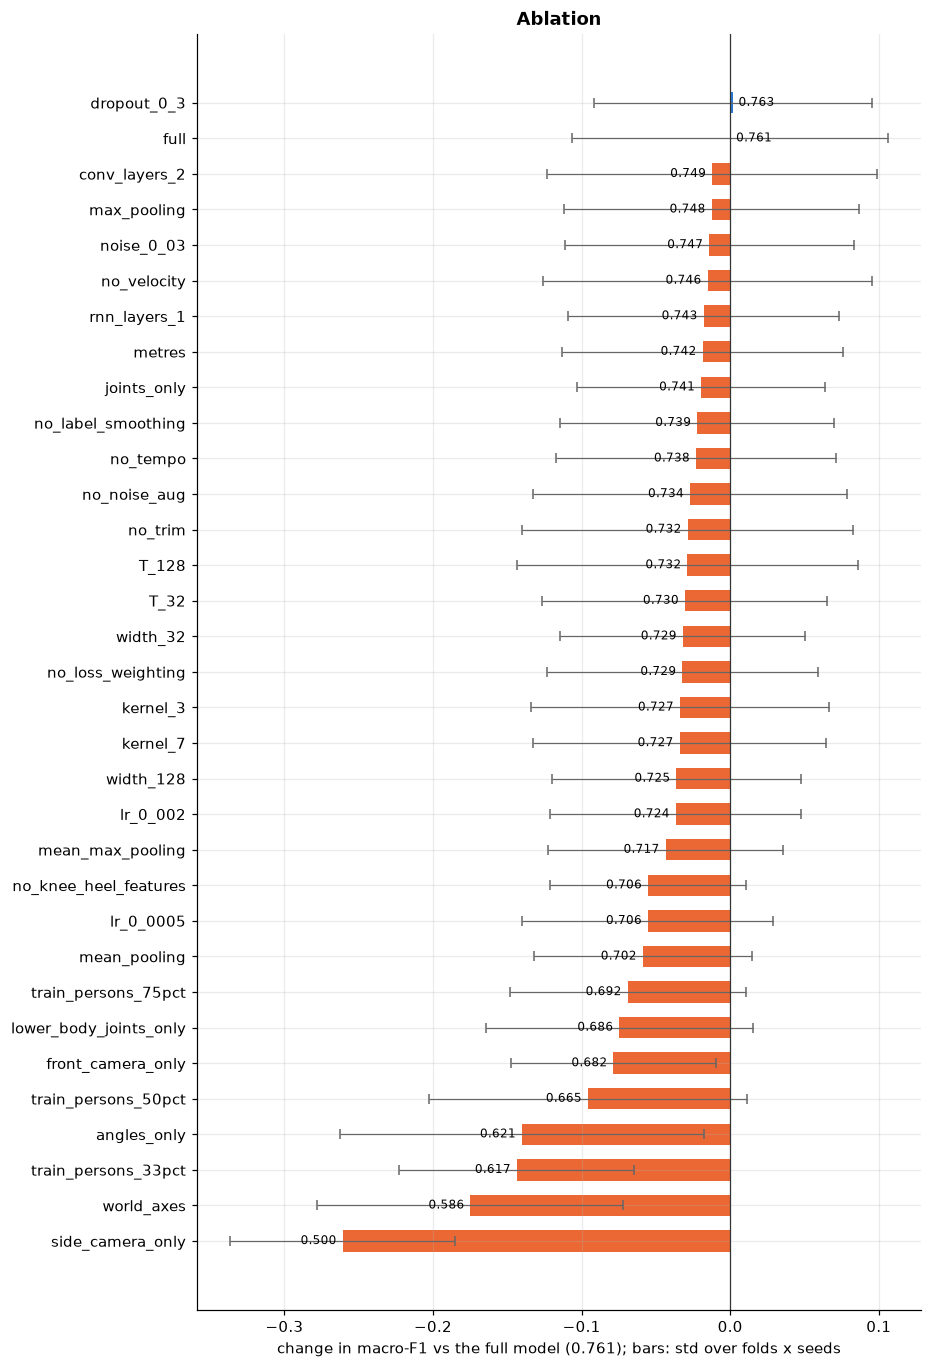

In [5]:
viz.ablation(abl, FIG, name=f"ablation_{best}"); plt.show()

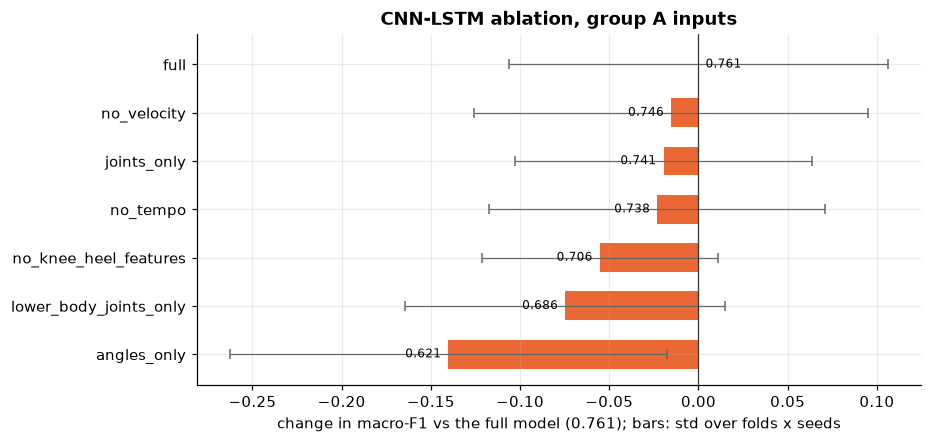

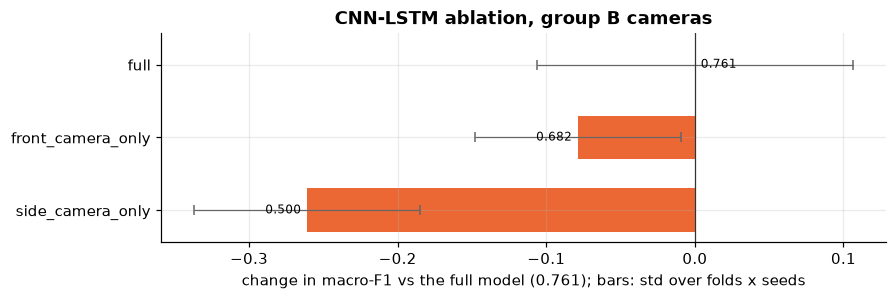

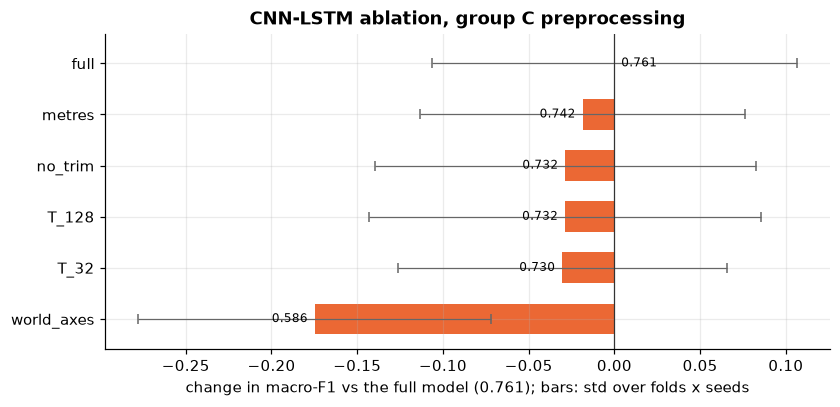

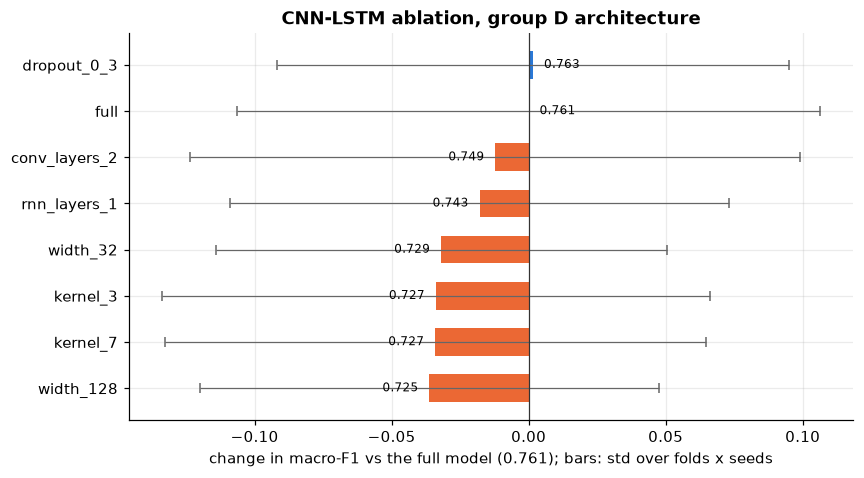

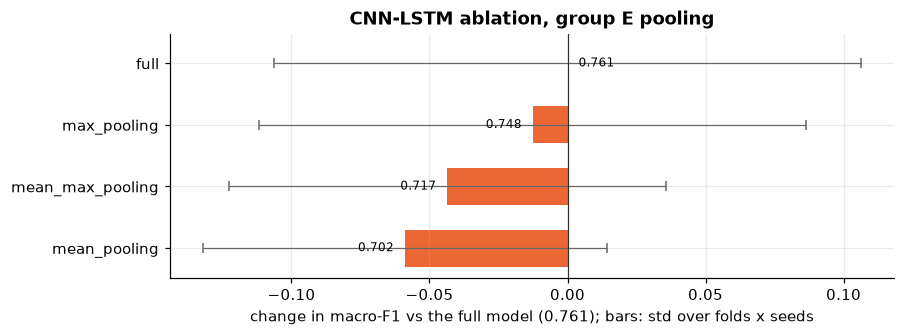

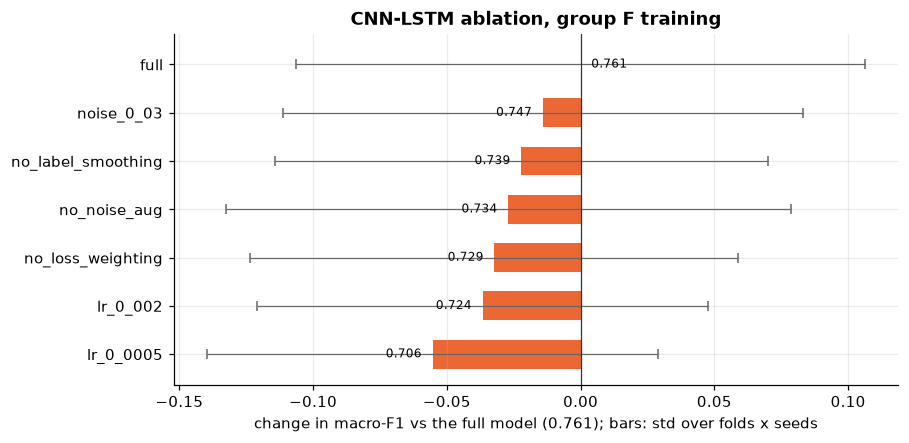

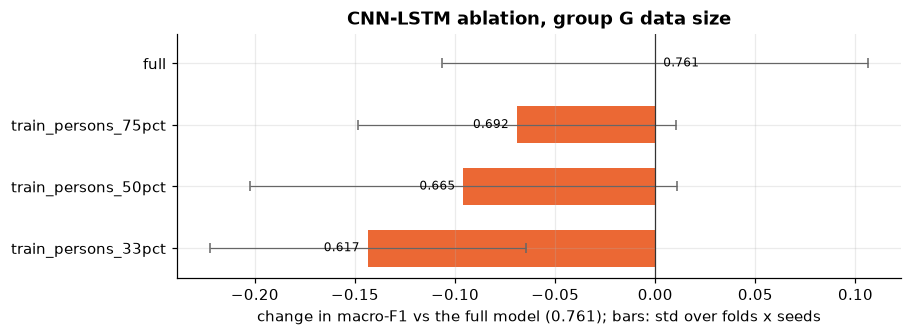

In [6]:
for g in sorted(set(abl["group"]) - {"reference"}):
    sub = pd.concat([abl[abl["variant"] == "full"], abl[abl["group"] == g]])
    viz.ablation(sub, FIG, name=f"ablation_{best}_{g.split()[0]}"); plt.title(f"{nice(best)} ablation, group {g}"); plt.show()

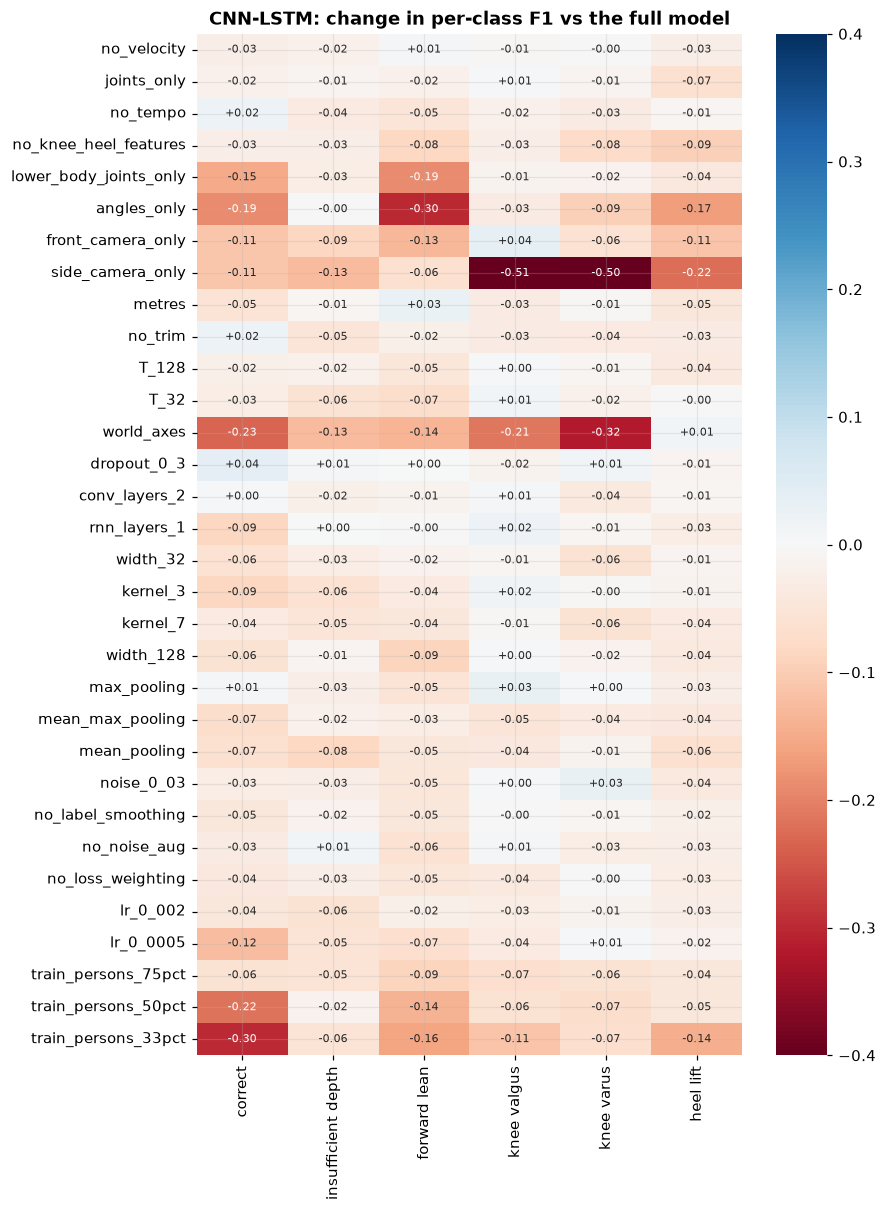

In [7]:
pc_full = np.array(full["per_class_f1"])
M = pd.DataFrame({v: np.array(read_json(RUN / v / best / "summary.json")["per_class_f1"]) - pc_full for v in abl["variant"] if v != "full"},
                 index=[c.replace("_", " ") for c in full["classes"]]).T
fig, ax = plt.subplots(figsize=(8, 0.33 * len(M) + 1.5))
sns.heatmap(M, annot=True, fmt="+.2f", cmap="RdBu", center=0, vmin=-0.4, vmax=0.4, ax=ax, annot_kws={"fontsize": 7})
ax.set_title(f"{nice(best)}: change in per-class F1 vs the full model"); viz.save(fig, FIG, f"ablation_per_class_{best}"); plt.show()

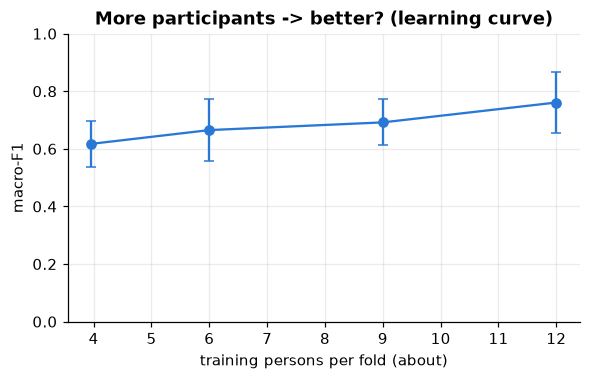

In [8]:
# learning curve over the number of training persons (group G)
lc = abl[abl["variant"].isin(["train_persons_33pct", "train_persons_50pct", "train_persons_75pct", "full"])].copy()
lc["fraction"] = lc["variant"].map({"train_persons_33pct": 0.33, "train_persons_50pct": 0.5, "train_persons_75pct": 0.75, "full": 1.0})
lc = lc.sort_values("fraction")
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.errorbar(lc["fraction"] * 12, lc["macro_f1"], yerr=lc["macro_f1_std"], marker="o", color=viz.ATTN, capsize=3)
ax.set(xlabel="training persons per fold (about)", ylabel="macro-F1", title="More participants -> better? (learning curve)", ylim=(0, 1))
viz.save(fig, FIG, f"learning_curve_persons_{best}"); plt.show()

## 3. Best configuration

In [9]:
NOT_CANDIDATES = {"full", "mean_pooling", "max_pooling", "mean_max_pooling", "side_camera_only", "front_camera_only",
                  "train_persons_33pct", "train_persons_50pct", "train_persons_75pct"}
cand = abl[(~abl["variant"].isin(NOT_CANDIDATES)) & (abl["delta"] >= 0.01) & (abl["wins"] > abl["losses"])].sort_values("delta", ascending=False)
display(cand)
clean = lambda o: {k: x for k, x in o.items() if k != "cv.seeds"}
chosen, overrides = "full", {}
if len(cand):
    chosen, overrides = cand.iloc[0]["variant"], clean(V[cand.iloc[0]["variant"]])
    combo, keys = {}, set()
    for v in cand["variant"]:
        o = clean(V[v])
        if not keys & set(o):
            combo.update(o); keys |= set(o)
    if combo != overrides:
        print("testing the combination:", combo)
        V["combined"], GROUP["combined"] = {**seeds_override, **combo}, "best config"
        monitor.launch_ablation(best, {"combined": V["combined"]}, RUN).wait()
        sc = read_json(RUN / "combined" / best / "summary.json")
        print(f"combined: macro-F1 {sc['macro_f1_mean']:.3f} vs single best {cand.iloc[0]['macro_f1']:.3f}")
        if sc["macro_f1_mean"] > cand.iloc[0]["macro_f1"]:
            chosen, overrides = "combined", combo
print("best configuration:", chosen, overrides or "(defaults)")

,variant,group,macro_f1,macro_f1_std,rec_macro_f1,delta,wins,losses,p_value,alpha_drop,median_best_epoch


best configuration: full (defaults)


In [10]:
best_cfg = apply_overrides(cfg, overrides)
s = read_json(RUN / chosen / best / "summary.json")
evidence = dict(model=best, name=nice(best), variant=chosen, overrides=overrides, macro_f1=s["macro_f1_mean"], macro_f1_std=s["macro_f1_std"],
                rec_macro_f1=s["rec_macro_f1_mean"], full_macro_f1=full["macro_f1_mean"], median_best_epoch=int(np.median(s["best_epochs"])),
                ablation_seeds=[0] if seeds_override else cfg["cv"]["seeds"])
best_cfg["final"] = dict(model=best, epochs=evidence["median_best_epoch"])
yaml.safe_dump(best_cfg, open(OUT / "best_config.yaml", "w"), sort_keys=False)
write_json(OUT / "best_config.json", evidence)
txt = (f"**Best configuration for {nice(best)}: `{chosen}`** {overrides if overrides else '(the default settings)'}: macro-F1 "
       f"{evidence['macro_f1']:.3f} ± {evidence['macro_f1_std']:.3f} (default {evidence['full_macro_f1']:.3f}). Final training length "
       f"{evidence['median_best_epoch']} epochs (median best epoch of the folds). Largest drops: "
       + ", ".join(f"{r.variant} ({r.delta:+.3f})" for r in abl.sort_values("delta").head(4).itertuples()) + ".")
(OUT / "summary.md").write_text(txt, encoding="utf-8"); display(Markdown(txt))

**Best configuration for CNN-LSTM: `full`** (the default settings): macro-F1 0.761 ± 0.106 (default 0.761). Final training length 15 epochs (median best epoch of the folds). Largest drops: side_camera_only (-0.261), world_axes (-0.175), train_persons_33pct (-0.144), angles_only (-0.140).